# Week 4 · k-means in pictures

The second kind of unsupervised learning: **clustering**, i.e. splitting the rows of $X$ into groups of similar points, with no labels. k-means is the standard first method and an exam favourite ("run 2 iterations of k-means on these 6 points"). One 6-point dataset is carried through the whole notebook, every step drawn and every number shown. **Reading:** ISL Ch. 12.4.1; StatQuest "K-means clustering".

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **cluster**: A group of points. k-means describes each cluster by one point, its **centroid** (the mean of its members).
- **assignment**: Which cluster each point belongs to: a label $c_i \in \{0, \dots, k - 1\}$ that k-means invents (no true labels exist).
- **inertia $J$**: The sum of squared distances from every point to its own centroid. Smaller means tighter clusters.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from figures import *
import checks; checks.load(globals(), "03")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** k-means is a loop of two steps, assign and update. Everything else is about starting it well, stopping it, and judging the result.

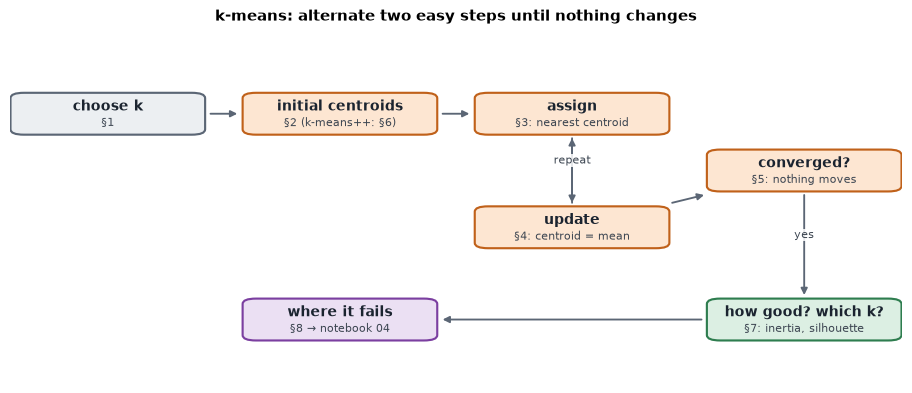

In [2]:
fig_kmeans_map()

| Section | What | Why it's here |
|---|---|---|
| E | start from the end | the **finished** k-means is just $k$ centroids; a **new** point goes to the nearest one |
| 1 | the goal: tight clusters | the one number k-means makes small, $J$ |
| 2 | initial centroids | k-means needs a starting guess |
| 3 | assign | each point joins its nearest centroid: your kNN distance table again |
| 4 | update | each centroid moves to its members' mean, and why the mean |
| 5 | the loop by hand | the exam drill: 2 iterations on 6 points; why it always stops; why it can stop in the wrong place |
| 6 | k-means++ | a smarter start that avoids most bad answers |
| 7 | choosing k | elbow and silhouette, with one silhouette by hand |
| 8 | where k-means fails | the three weaknesses that notebook `04` fixes |
| 9 | scikit-learn, real data | iris, with the labels hidden |
| 10 | build it yourself | 7 exercises; the last is k-means as a class (`fit`, `predict`), checked against scikit-learn |

## 0. Recap first · 10 min, closed book

**Quick check:** PCA: covariance $\begin{pmatrix} 2.5 & 2 \\ 2 & 2.5 \end{pmatrix}$. Its eigenvalues, and the share of variance PC1 keeps?

<details><summary>Answer</summary>

$(2.5 - \lambda)^2 = 4$ gives $\lambda = 4.5$ and $0.5$; PC1 keeps $\frac{4.5}{5} = 90\%$. [02 §5 ↗](02_pca.ipynb)

</details>

**Quick check:** Why standardize before PCA (usually)?

<details><summary>Answer</summary>

PCA chases variance, so a feature in big units dominates just because its numbers are big. [02 §10 ↗](02_pca.ipynb)

</details>

**Quick check:** `X` is `(n, d)` and `C` is `(k, d)`. Shape of `X[:, None, :] - C[None, :, :]`, and of its squared sum over `axis=2`?

<details><summary>Answer</summary>

`(n, k, d)` and `(n, k)`: one squared distance per (point, centroid) pair. It's your kNN distance table with the centroids as the "training points". [Week 3 · 02 §7 ↗](../week3/02_knn_and_numpy_workout.ipynb)

</details>

**Quick check:** `labels = np.array([0, 1, 0])`, `X = np.array([[1, 2], [5, 5], [3, 4]])`. What is `X[labels == 0].mean(axis=0)`?

<details><summary>Answer</summary>

Rows 0 and 2: `[[1, 2], [3, 4]]`, whose mean is `[2. 3.]`. A mask on axis 0 keeps whole rows (your find from Week 3 · 02 ex. 17). [00 §A6 ↗](00_week3_review.ipynb)

</details>

**Quick check:** The **finished** AdaBoost model is `[(2.5, -1, 0.549), (6.5, -1, 0.805), (4.5, 1, 0.693)]` (threshold, sign, vote). Predict $x = 5.5$.

<details><summary>Answer</summary>

Each stump votes: $x > 2.5$ with $s = -1$ gives $-1$; $x \le 6.5$ gives $-s = +1$; $x > 4.5$ with $s = +1$ gives $+1$. $F = -0.549 + 0.805 + 0.693 = 0.949 > 0$, so **$+1$**. The finished model is just a list of (threshold, sign, vote); predicting is a weighted vote. [01 §7 ↗](01_boosting_step_by_step.ipynb)

</details>

**Quick check:** AdaBoost: $\varepsilon = 0.25$. What is $\alpha$?

<details><summary>Answer</summary>

$\frac{1}{2}\ln\frac{0.75}{0.25} = \frac{1}{2}\ln 3 = 0.549$. [01 §5 ↗](01_boosting_step_by_step.ipynb)

</details>

## E. Start from the end: the finished k-means, and a new point

Same habit as PCA ([02 §E ↗](02_pca.ipynb)): first the finished model and what it does with a new input, then how it's built.

**What a fitted k-means stores**

| Stored (scikit-learn name) | For the 6 points in §1 | Where it comes from |
|---|---|---|
| `cluster_centers_`: $k$ centroids, shape $(k, d)$ | (1.333, 1.333) and (4.667, 3.333) | §2–5 |
| `labels_`: the cluster of each **training** point | 0 0 0 1 1 1 | §3 |
| `inertia_`: $J$ at the end | 2.67 | §1, §5 |

For new points only the centroids matter: **the finished model is $k$ points.**

**What it does with a new point (predict)**

- New point $(3.5, 2)$. Distance to centroid 0: $\sqrt{(3.5 - 1.333)^2 + (2 - 1.333)^2} = \sqrt{4.694 + 0.444} = 2.267$.
- Distance to centroid 1: $\sqrt{(3.5 - 4.667)^2 + (2 - 3.333)^2} = \sqrt{1.361 + 1.778} = 1.772$.
- The smaller one wins: **cluster 1**. That's `predict`. It does **not** move the centroids; only `fit` does.

🖼 **Picture.** The finished model (two centroids and the regions they own) and a new point.

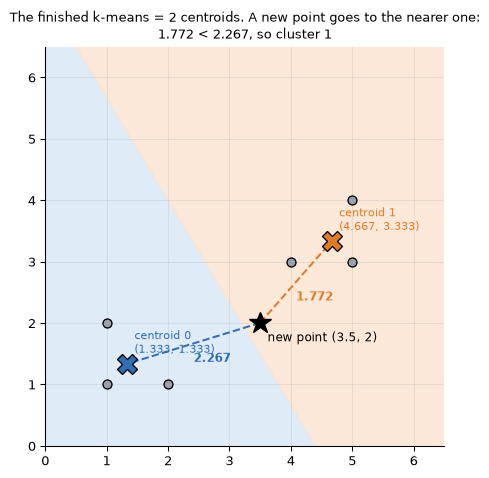

In [3]:
fig_kmeans_new_point()

In [ ]:
from sklearn.cluster import KMeans
XK = np.array([[1, 1], [1, 2], [2, 1], [4, 3], [5, 4], [5, 3]], dtype=float)
km = KMeans(n_clusters=2, init=np.array([[1, 1], [2, 1.0]]), n_init=1).fit(XK) #init=... gives explicit starting centroids, n_init=1 runs the algorithm once
#.fit(XK) runs Lloyd’s algorithm : : assign each point to its nearest centroid, recompute each centroid as the mean of its points, and repeat until nothing changes.
print(km.cluster_centers_.round(3).tolist())                    # → [[1.333, 1.333], [4.667, 3.333]]
print(km.predict(np.array([[3.5, 2.0]])), km.transform(np.array([[3.5, 2.0]])).round(3))   # → [1] [[2.267 1.772]]
#km.transform(P) returns the Euclidean distance from each point to each centroid

[[1.333, 1.333], [4.667, 3.333]]
[1] [[2.267 1.772]]


`transform` gives the distances to every centroid, the table `predict` takes the `argmin` of. Notice the answer is just "1", even though 1.772 vs 2.267 is a close call: k-means can't say how sure it is. Gaussian mixtures ([04 §3 ↗](04_hierarchical_dbscan_gmm.ipynb)) give a probability instead. **The rest of the notebook answers: where do the centroids come from?**

## Lloyd's Algorithm (standard k-means)

**Goal.** Given data points $x_1, \dots, x_n \in \mathbb{R}^d$ and a number of clusters $k$, find centroids $\mu_1, \dots, \mu_k$ and an assignment $c(i) \in \{1, \dots, k\}$ for each point that minimize the **within-cluster sum of squares** (WCSS, called `inertia_` in sklearn):

$$
J(c, \mu) = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2
$$

Minimizing $J$ exactly is NP-hard, so Lloyd's algorithm minimizes it by **alternating** between the two sets of variables, holding one fixed while optimizing the other.

### Steps

1. **Initialize** the centroids $\mu_1^{(0)}, \dots, \mu_k^{(0)}$ (random points, k-means++, or user-supplied via `init=`).

2. **Assignment step.** Holding the centroids fixed, send each point to its nearest centroid:
$$
c^{(t)}(i) = \arg\min_{j} \lVert x_i - \mu_j^{(t)} \rVert^2
$$

3. **Update step.** Holding the assignments fixed, move each centroid to the mean of its points:
$$
\mu_j^{(t+1)} = \frac{1}{|C_j|} \sum_{i \in C_j} x_i, \qquad C_j = \{\, i : c^{(t)}(i) = j \,\}
$$

4. **Repeat** steps 2–3 until the assignments stop changing (or the centroids move less than a tolerance `tol`, or `max_iter` is reached).

### Why it works

- **Each step can only lower $J$.** In the assignment step, picking the nearest centroid minimizes each term $\lVert x_i - \mu_{c(i)} \rVert^2$ individually. In the update step, the mean is the point minimizing $\sum_{i \in C_j} \lVert x_i - \mu \rVert^2$ (set the gradient $-2\sum_{i \in C_j}(x_i - \mu)$ to zero).
- **It must terminate.** $J$ is non-increasing and there are only finitely many possible assignments ($k^n$), so the algorithm reaches a fixed point in finitely many iterations.

### Caveats

- **Local, not global, optimum.** The result depends on initialization. That's why sklearn defaults to k-means++ seeding and runs several restarts (`n_init`), keeping the run with the lowest $J$.
- **Empty clusters** can occur if no point is assigned to a centroid. Implementations handle this by reseeding it, e.g. at the point farthest from its centroid.
- **Implicit assumptions.** Squared Euclidean distance favors roughly spherical, similarly sized clusters, and the result is sensitive to feature scaling, so standardize features first when units differ.
- **Cost.** Each iteration is $O(nkd)$.

### Example (data `XK` above)

Starting from $\mu_1 = (1,1)$, $\mu_2 = (2,1)$:

| Iteration | Cluster 1 | Cluster 2 | Centroids after update |
|---|---|---|---|
| 1 | $(1,1), (1,2)$ | $(2,1), (4,3), (5,4), (5,3)$ | $(1, 1.5)$, $(4, 2.75)$ |
| 2 | $(1,1), (1,2), (2,1)$ | $(4,3), (5,4), (5,3)$ | $(1.333, 1.333)$, $(4.667, 3.333)$ |
| 3 | no change, so it has converged | | |

## 1. The goal: tight clusters

**k-means splits the points into $k$ groups so that the points are as close as possible to the mean of their own group.** Formally, it makes the inertia $J$ small:

$$
J = \sum_{i=1}^{n} \big\lVert x_i - \mu_{c_i} \big\rVert^2
$$

Here $c_i$ is the cluster of point $i$ and $\mu_{c_i}$ is that cluster's centroid. Each point pays the squared distance to its own centroid. $J$ is small when every cluster is tight.

**Our data:** 6 points; by eye they form two groups, A–C bottom left and D–F top right. The task, $k = 2$, is to find them without being told.

|  | A | B | C | D | E | F |
|---|---|---|---|---|---|---|
| $x_1$ | 1 | 1 | 2 | 4 | 5 | 5 |
| $x_2$ | 1 | 2 | 1 | 3 | 4 | 3 |

In [5]:
XK = np.array([[1, 1], [1, 2], [2, 1], [4, 3], [5, 4], [5, 3]], dtype=float)   # (6, 2), points A–F

## 2. Initial centroids

**k-means needs $k$ starting centroids. The simplest choice is $k$ of the data points, picked at random.**

To make the loop interesting, we start from a **bad** pick: A $(1, 1)$ and C $(2, 1)$, both in the bottom-left group. Watch k-means fix it. (§5 shows starts it can't fix, and §6 how to avoid them.)

In [32]:
C = np.array([[1, 1], [2, 1]], dtype=float)     # (2, 2): centroid 0 = A, centroid 1 = C

## 3. Step 1, assign: every point joins its nearest centroid

**Compute the distance from every point to every centroid, an $n \times k$ table, and give each point the label of the closest centroid.**

$$
c_i = \arg\min_{j} \lVert x_i - \mu_j \rVert^2
$$

| Point | distance to $\mu_0 = (1, 1)$ | distance to $\mu_1 = (2, 1)$ | nearest | $c_i$ |
|---|---|---|---|---|
| A (1, 1) | **0.000** | 1.000 | $\mu_0$ | 0 |
| B (1, 2) | **1.000** | 1.414 | $\mu_0$ | 0 |
| C (2, 1) | 1.000 | **0.000** | $\mu_1$ | 1 |
| D (4, 3) | 3.606 | **2.828** | $\mu_1$ | 1 |
| E (5, 4) | 5.000 | **4.243** | $\mu_1$ | 1 |
| F (5, 3) | 4.472 | **3.606** | $\mu_1$ | 1 |

D by hand: to $\mu_0$, $\sqrt{(4 - 1)^2 + (3 - 1)^2} = \sqrt{13} = 3.606$; to $\mu_1$, $\sqrt{(4 - 2)^2 + (3 - 1)^2} = \sqrt 8 = 2.828$. The second is smaller, so D joins cluster 1.

In [7]:
D = np.sqrt(((XK[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))   # (6, 1, 2) - (1, 2, 2) → (6, 2, 2) → (6, 2)
print(D.round(3))
# → [[0.    1.   ]
#    [1.    1.414]
#    [1.    0.   ]
#    [3.606 2.828]
#    [5.    4.243]
#    [4.472 3.606]]
labels = D.argmin(axis=1)          # choose among the centroids → axis 1 (your axis rule)
print(labels)                      # → [0 0 1 1 1 1]

[[0.    1.   ]
 [1.    1.414]
 [1.    0.   ]
 [3.606 2.828]
 [5.    4.243]
 [4.472 3.606]]
[0 0 1 1 1 1]


### what goes on inside the arrays
### Step 2: Subtract, which broadcasts to `(6, 2, 2)`

NumPy compares shapes axis by axis: `(6, 1, 2)` vs `(1, 2, 2)`. Wherever one side is 1, it gets stretched to match, so the result has shape `(6, 2, 2)` with

$$
\text{diff}[i, j, :] = XK[i] - C[j]
$$

```
             vs C[0]=(1,1)   vs C[1]=(2,1)
i=0 (1,1)  →   [ 0,  0]        [-1,  0]
i=1 (1,2)  →   [ 0,  1]        [-1,  1]
i=2 (2,1)  →   [ 1,  0]        [ 0,  0]
i=3 (4,3)  →   [ 3,  2]        [ 2,  2]
i=4 (5,4)  →   [ 4,  3]        [ 3,  3]
i=5 (5,3)  →   [ 4,  2]        [ 3,  2]
```

### Step 3: `** 2` squares elementwise, shape still `(6, 2, 2)`

```
i=0  →   [ 0,  0]   [ 1,  0]
i=1  →   [ 0,  1]   [ 1,  1]
i=2  →   [ 1,  0]   [ 0,  0]
i=3  →   [ 9,  4]   [ 4,  4]
i=4  →   [16,  9]   [ 9,  9]
i=5  →   [16,  4]   [ 9,  4]
```

### Step 4: `.sum(axis=2)` adds over coordinates, giving shape `(6, 2)`

Axis 2 is the $(x, y)$ axis, so each pair collapses to $\Delta x^2 + \Delta y^2$:

```
       C[0]  C[1]
i=0  [  0,    1 ]
i=1  [  1,    2 ]
i=2  [  1,    0 ]
i=3  [ 13,    8 ]
i=4  [ 25,   18 ]
i=5  [ 20,   13 ]
```

### Step 5: `np.sqrt` gives the Euclidean distances

```
D =
[[0.    , 1.    ],
 [1.    , 1.414 ],
 [1.    , 0.    ],
 [3.606 , 2.828 ],
 [5.    , 4.243 ],
 [4.472 , 3.606 ]]
```

`D[i, j]` is the distance from point $i$ to centroid $j$.

The assignment carves the plane into regions, one per centroid, with straight borders halfway between centroids. You'll see them as the coloured backgrounds in §5. Since only the order matters for `argmin`, you can skip the square root, as you did in kNN ([00 §A1 ↗](00_week3_review.ipynb)).

## 4. Step 2, update: every centroid moves to the mean of its members

**Replace each centroid by the average of the points assigned to it.**

$$
\mu_j = \frac{1}{\lvert C_j \rvert}\sum_{i \in C_j} x_i
$$

Cluster 0 holds A and B: $\mu_0 = \big(\frac{1 + 1}{2}, \frac{1 + 2}{2}\big) = (1, 1.5)$. Cluster 1 holds C, D, E, F: $\mu_1 = \big(\frac{2 + 4 + 5 + 5}{4}, \frac{1 + 3 + 4 + 3}{4}\big) = (4, 2.75)$.

**Why the mean?** With the assignments fixed, cluster $j$ contributes $\sum_{i \in C_j} \lVert x_i - \mu_j \rVert^2$ to $J$. Set its gradient to zero: $-2\sum_{i \in C_j} (x_i - \mu_j) = 0$, so $\mu_j = $ the mean. **The mean is the single point closest (in squared distance) to a group of points**, the same reason $F_0 = \bar y$ in gradient boosting ([01 §8 ↗](01_boosting_step_by_step.ipynb)).

In [8]:
C = np.array([XK[labels == j].mean(axis=0) for j in range(2)])   # the rows of each cluster, averaged
print(C)
# → [[1.   1.5 ]
#    [4.   2.75]]

[[1.   1.5 ]
 [4.   2.75]]


## 5. The loop, by hand: two iterations

**Repeat assign → update until the assignments stop changing.**

🖼 **Picture.** Start, then each step. Background colour: which centroid is nearest (the assignment regions). ✕ = centroids; arrows show them moving. $J$ is printed for each step.

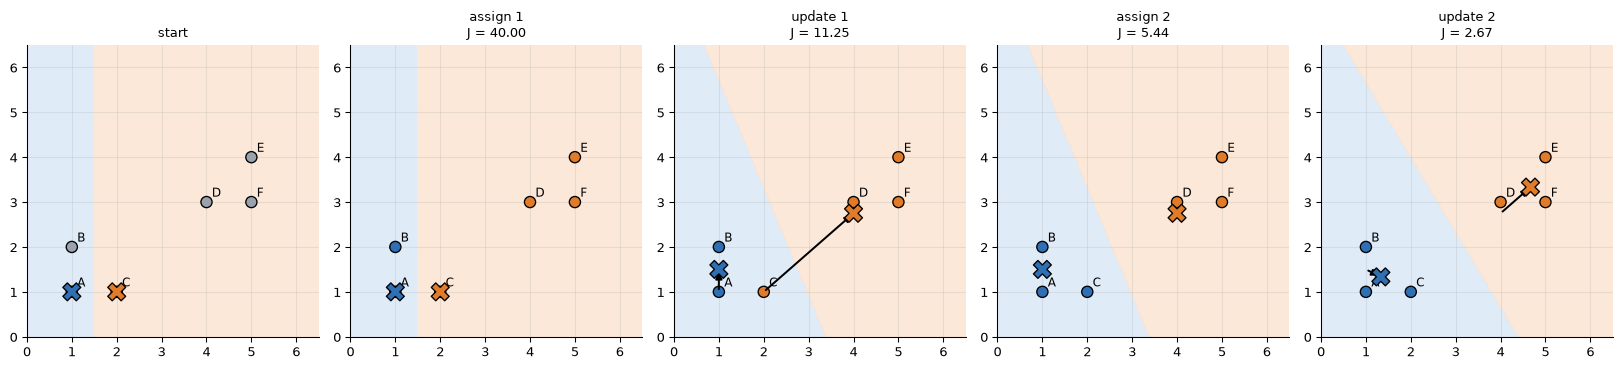

In [9]:
fig_kmeans_iterations()

| Step | Centroids | Labels A–F | Inertia $J$ | What happened |
|---|---|---|---|---|
| start | (1, 1), (2, 1) |  |  | both in the same group: a bad start |
| assign 1 | (1, 1), (2, 1) | 0 0 1 1 1 1 | 40.00 | C, D, E, F all join centroid 1 |
| update 1 | (1, 1.5), (4, 2.75) | 0 0 1 1 1 1 | 11.25 | centroid 1 jumps toward D, E, F |
| assign 2 | (1, 1.5), (4, 2.75) | **0 0 0** 1 1 1 | 5.44 | C switches: 1.118 from $\mu_0$ vs 2.658 from $\mu_1$ |
| update 2 | (1.333, 1.333), (4.667, 3.333) | 0 0 0 1 1 1 | 2.67 | both centroids move to the true groups |
| assign 3 | same | 0 0 0 1 1 1 | 2.67 | **nothing changes: converged** |

$J$ by hand after update 2: cluster 0's centroid is $(1.333, 1.333)$, so A pays $0.333^2 + 0.333^2 = 0.222$, B pays $0.333^2 + 0.667^2 = 0.556$ and C pays $0.556$. Cluster 1 is the mirror image. Total $2 \times (0.222 + 0.556 + 0.556) = 2.67$.

**Why it always stops.** Each assign step can only lower $J$ (every point moves to a closer centroid, or stays), and each update step can only lower $J$ (the mean is the best centre, §4). $J$ never goes up, and there are only finitely many ways to split $n$ points into $k$ groups, so it must stop.

**But it can stop in the wrong place.** "Can't improve by one assign or one update" is a **local** minimum, not necessarily the best clustering:

🖼 **Picture.** The same 300 points, three different starts. The middle one gets stuck with two centroids in one group and one centroid serving two groups: $J = 1309$ instead of 501.

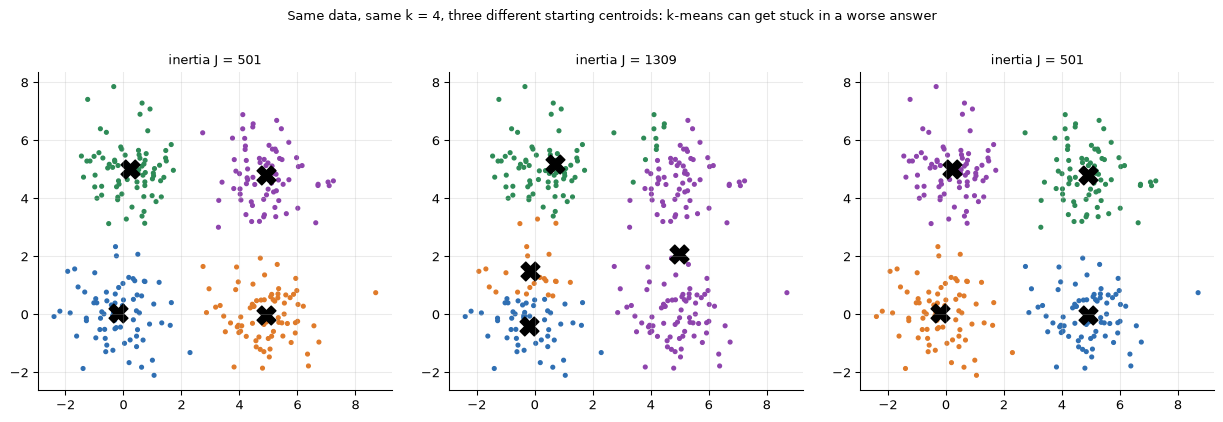

In [10]:
fig_kmeans_local()

The fix is to run k-means several times from different starts and keep the run with the smallest $J$. That's scikit-learn's `n_init` (10 starts by default in many versions).

## 6. A better start: k-means++

**k-means++ picks the first centroid at random, then picks each next one at random with probability proportional to its squared distance $D^2$ from the nearest centroid chosen so far.** Far-away points are likely picks, so the starting centroids spread out.

$$
P(\text{pick } x_i) = \frac{D(x_i)^2}{\sum_j D(x_j)^2}
$$

🖼 **Picture.** Suppose A is picked first. Points near A have tiny $D^2$; E, F and D, in the other group, have the biggest chances.

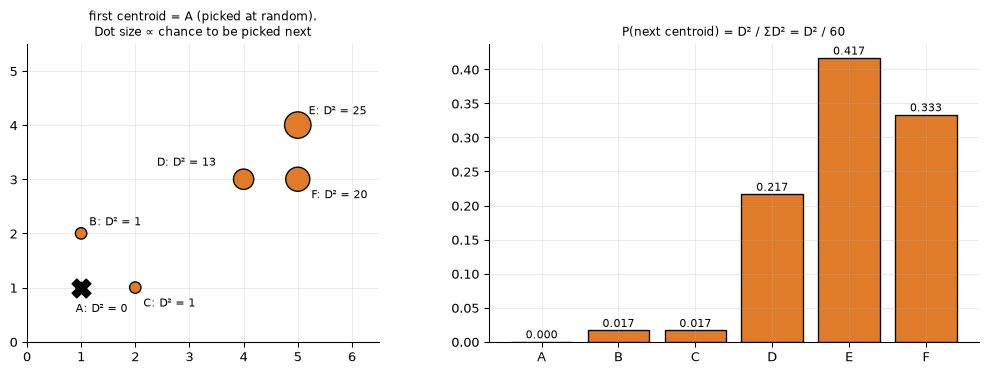

In [11]:
fig_kmeanspp()

By hand: the squared distances from A are $0, 1, 1, 13, 25, 20$, which sum to 60. So E is picked with probability $\frac{25}{60} = 0.417$, F with $0.333$, D with $0.217$; with probability $0.967$, the second centroid lands in the other group. scikit-learn uses k-means++ by default (`init="k-means++"`).

## 7. Choosing k

**$J$ always falls as $k$ grows (with $k = n$, every point is its own centroid and $J = 0$), so you can't just minimize $J$. Two common checks: the elbow, and the silhouette.**

**The silhouette of one point** compares how close it is to its own cluster with how close it is to the nearest other cluster:

$$
s(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)}
$$

$a(i)$ is the mean distance from point $i$ to the other members of its own cluster, and $b(i)$ the mean distance to the members of the nearest **other** cluster. $s$ is near 1 when the point sits snugly in its cluster, near 0 on a border, and negative when it's probably in the wrong cluster.

The silhouette asks, for each point: **"Am I closer to my own cluster than to the next-best cluster?"** It turns that comparison into a score between $-1$ and $1$.

### The formula (per point $i$)

- $a(i)$ is the **average distance from $i$ to the other points in its own cluster**. It measures cohesion, and small is good.
- $b(i)$ is the **average distance from $i$ to the points of the nearest *other* cluster**. You compute the average to each other cluster and take the minimum. It measures separation, and large is good.

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}
$$

### How to read a single $s(i)$

| $s(i)$ | Meaning |
|---|---|
| close to **1** | $a \ll b$: tight inside its cluster, far from the neighbor. Well clustered. |
| around **0** | $a \approx b$: sits on the boundary between two clusters. |
| **negative** | $a > b$: it's on average closer to another cluster. Probably assigned to the wrong cluster. |

🖼 **Picture.** Point C in the final clustering. Solid: distances to its own cluster (A, B). Dashed: distances to the other cluster (D, E, F).

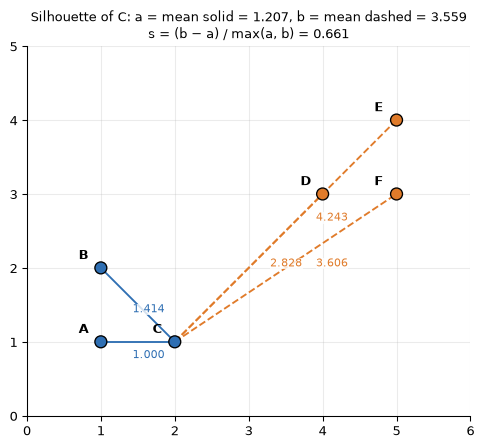

In [12]:
fig_silhouette_point()

- $a(C) = \frac{1.000 + 1.414}{2} = 1.207$: distances to A and B.
- $b(C) = \frac{2.828 + 4.243 + 3.606}{3} = 3.559$: distances to D, E and F.
- $s(C) = \frac{3.559 - 1.207}{3.559} = 0.661$: comfortably in the right cluster.

Average $s(i)$ over all points to score a whole clustering, and compare $k$ values:

🖼 **Picture.** 400 points in 4 groups. Middle: $J$ against $k$, with a clear bend (the "elbow") at 4. Right: the mean silhouette, highest at $k = 4$.

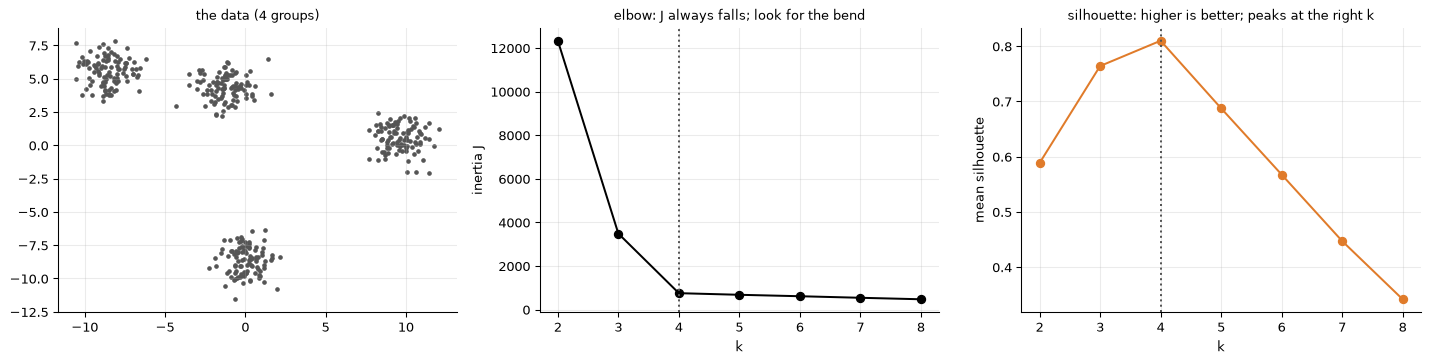

In [13]:
fig_elbow_silhouette()

## 8. Where k-means fails

**k-means describes each cluster by one centre and uses straight-line distance, so it assumes round blobs of similar size, on comparable scales.** Break any of those and it fails:

🖼 **Picture.** Left: curved shapes, which it cuts straight through. Middle: a widely spread cluster next to a tight one; the border is drawn halfway between the centroids, so it eats into the big one. Right: unscaled features; the real split is left/right, but $x_2$ has bigger numbers, so k-means splits top/bottom.

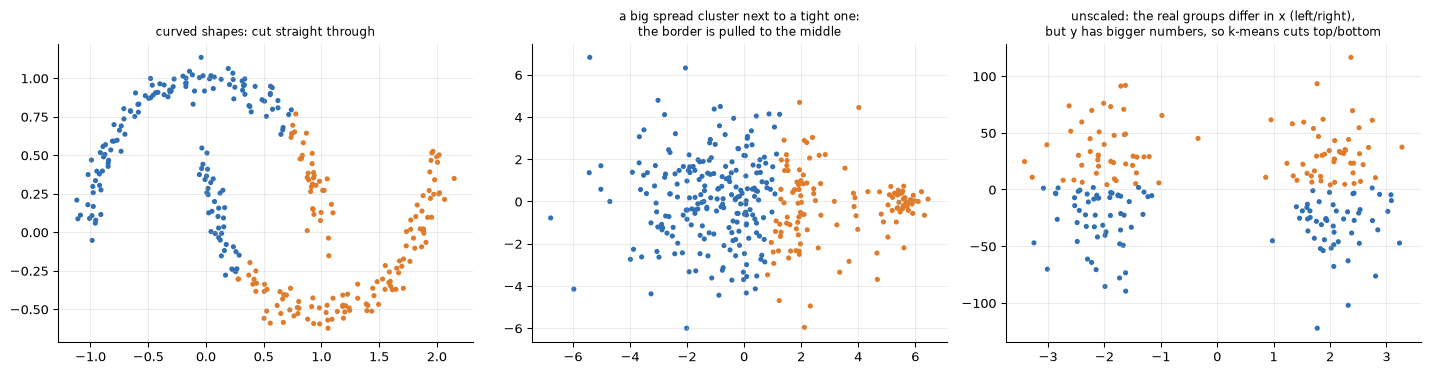

In [14]:
fig_kmeans_failures()

| Problem | Fix | Where |
|---|---|---|
| features on different scales | standardize first | now (§9) |
| you don't know $k$ | hierarchical clustering: look at the whole tree, then cut | `04` §1 |
| curved shapes, or noise points that belong nowhere | DBSCAN: clusters as dense regions | `04` §2 |
| overlapping, stretched (elliptical) clusters, or you want probabilities | Gaussian mixtures, fitted with EM | `04` §3 |

## 9. k-means in scikit-learn, on real data

The iris data: 150 flowers, 4 measurements each, 3 species. We **hide the species**, cluster the scaled measurements, and only afterwards compare the clusters with the species:

In [15]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
iris = load_iris()
Z = StandardScaler().fit_transform(iris.data)            # (150, 4)
for k in [2, 3, 4, 5]:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    print(k, round(km.inertia_, 1), round(silhouette_score(Z, km.labels_), 3))
# → 2 222.4 0.582
#   3 139.8 0.46
#   4 114.1 0.387
#   5 90.8 0.346

2 222.4 0.582
3 139.8 0.46
4 114.1 0.387
5 90.8 0.346


The silhouette prefers $k = 2$, not 3. That's honest information: two of the species (versicolor and virginica) overlap in these measurements, so the data really looks like 2 groups. **Clustering finds structure in $X$; it doesn't promise to find the labels you had in mind.** Here's $k = 3$ against the species:

In [16]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z)
print(pd.crosstab(iris.target_names[iris.target], km.labels_))
# → col_0        0   1   2
#   row_0
#   setosa       0  50   0
#   versicolor  39   0  11
#   virginica   14   0  36

col_0        0   1   2
row_0                 
setosa       0  50   0
versicolor  39   0  11
virginica   14   0  36


Setosa gets its own cluster perfectly. The other two species are mostly separated, with 25 flowers on the wrong side. The cluster numbers (0, 1, 2) are arbitrary names; only which flowers end up together matters.

## 10. Build it yourself

`X` is `(n, d)`, `C` (centroids) is `(k, d)`, `labels` is `(n,)` with whole numbers $0, \dots, k - 1$. Use the 6 points `XK` from §1 to test as you go.

✏️ **Exercise 1 · Assign.** Return the index of the nearest centroid for every point. **Shape `(n,)`.** Build the `(n, k)` squared-distance table with broadcasting, then `argmin` along the axis you're choosing among.

**Example**: what goes in, and what should come out:
```python
C = np.array([[1, 1], [2, 1.0]])       # 2 centroids, (2, 2)
assign(XK, C)                          # → [0 0 1 1 1 1]   (assign 1 in §5)
```

In [51]:
def assign(X, C):
    labels = np.argmin(((X[:,None,:] - C[None,:,:])**2).sum(axis=2), axis=1) #헷갈리면 -> §3에 나오는 what goes on inside the array 다시 확인
    return labels 

In [36]:
check(1)

Exercise 1: PASS


✏️ **Exercise 2 · Update.** Return the mean of each cluster's points, cluster 0 first. **Shape `(k, d)`.** (Assume no cluster is empty.)

**Example**: what goes in, and what should come out:
```python
update(XK, np.array([0, 0, 1, 1, 1, 1]), 2)
# → [[1.   1.5 ]
#    [4.   2.75]]
```

In [52]:
def update(X, labels, k):
    l = []
    for i in np.unique(labels):
        update = X[labels == i].mean(axis=0)
        l.append(update)
    return np.array(l)

In [53]:
check(2)

Exercise 2: PASS


✏️ **Exercise 3 · Inertia.** $J$: the sum over all points of the squared distance to their **own** centroid. **Shape `()`.** Hint: `C[labels]` gives each point's centroid as an `(n, d)` array (fancy indexing).

**Example**: what goes in, and what should come out:
```python
inertia(XK, np.array([[1, 1.5], [4, 2.75]]), np.array([0, 0, 1, 1, 1, 1]))     # → 11.25
```

In [54]:
def inertia(X, C, labels):
    l = []
    for i in np.unique(labels):
        dist = ((X[labels == i] - C[i])**2).sum() #X[labels == i] -> (m,d) / C[i] -> (1,d)
        l.append(dist)
    return np.array(l).sum()

In [55]:
check(3)

Exercise 3: PASS


✏️ **Exercise 4 · k-means.** Starting from centroids `C`: assign; then repeat up to `iters` times: update, assign again, and **stop early** if no label changed. Return `(C, labels)`. Don't change the `C` that was passed in (`C = C.copy()` first).

**Example**: what goes in, and what should come out:
```python
C_final, labels = kmeans(XK, np.array([[1, 1], [2, 1.0]]), 10)
C_final    # → [[1.333 1.333]
           #    [4.667 3.333]]
labels     # → [0 0 0 1 1 1]
```

In [56]:
def assign(X, C):
    labels = np.argmin(((X[:,None,:] - C[None,:,:])**2).sum(axis=2), axis=1) #헷갈리면 -> §3에 나오는 what goes on inside the array 다시 확인
    return labels 

def update(X, labels, k):
    l = []
    for i in np.unique(labels):
        update = X[labels == i].mean(axis=0)
        l.append(update)
    return np.array(l)

def inertia(X, C, labels):
    l = []
    for i in np.unique(labels):
        dist = ((X[labels == i] - C[i])**2).sum() #X[labels == i] -> (m,d) / C[i] -> (1,d)
        l.append(dist)
    return np.array(l).sum()

In [59]:
def kmeans(X, C, iters):
    C = C.copy()
    k = len(C)                          # number of clusters = number of centroids
    labels = assign(X, C)               # assign once before the loop
    for _ in range(iters):
        C = update(X, labels, k)        # 1. update
        new_labels = assign(X, C)       # 2. assign again
        if np.array_equal(new_labels, labels):   # 3. stop if no label changed
            break
        labels = new_labels
    return C, labels

In [60]:
check(4)

Exercise 4: PASS


✏️ **Exercise 5 · k-means++ probabilities.** `C` holds the centroids picked so far (`(m, d)`, $m \ge 1$). For every point, take the squared distance to its **nearest** centroid, then divide by the total. **Shape `(n,)`**, sums to 1.

**Example**: what goes in, and what should come out:
```python
kmeanspp_probs(XK, np.array([[1, 1.0]]))
# → [0.     0.0167 0.0167 0.2167 0.4167 0.3333]     = [0, 1, 1, 13, 25, 20] / 60
```

In [ ]:
def assign(X, C):
    labels = np.argmin(((X[:,None,:] - C[None,:,:])**2).sum(axis=2), axis=1) #헷갈리면 -> §3에 나오는 what goes on inside the array 다시 확인
    return labels 

In [ ]:
def kmeanspp_probs(X, C): # X -> (n,d) C ->(m,d)
    dist = ((X[:,None,:]-C[None,:,:])**2).sum(axis = 2) #(n,m)
    labels = assign(X,C) #(n,) #we have to find the nearest centroids first -> use the assign function from above
    l = []
    for i in range(len(labels)):
        l.append(dist[i,labels[i]] ) #at end of iteration shape -> (n,)
    return np.array(l)/np.array(l).sum()

In [67]:
check(5)

Exercise 5: PASS


✏️ **Exercise 6 · Silhouette of one point.** $s(i) = \frac{b - a}{\max(a, b)}$. $a$: mean distance from point `i` to the **other** points of its own cluster. $b$: the smallest, over the other clusters, of the mean distance to that cluster's points. (Real distances, with the square root.)

**Example**: what goes in, and what should come out:
```python
silhouette_point(XK, np.array([0, 0, 0, 1, 1, 1]), 2)     # → 0.661   point C, as in §7
```

In [ ]:
def silhouette_point(X, labels, i):
    

In [28]:
check(6)

Exercise 6: something returned None. Not written yet, or a missing `return`?


**The whole model as a class**, the shape exam questions often use. `fit` runs your loop and stores what section E listed; `predict` does section E's two steps.

✏️ **Exercise 7 · Your own k-means class.** `__init__(self, init)` takes the starting centroids `(k, d)`. `fit(X, iters=100)` runs k-means from them (your exercise 4, or rewrite it), stores `self.cluster_centers_` `(k, d)`, `self.labels_` `(n,)` and `self.inertia_`, then **`return self`**. `predict(X)` returns the nearest stored centroid for each row, `(m,)`. The checker compares with its own reference run on random data.

**Example**: what goes in, and what should come out:
```python
km = MyKMeans(np.array([[1, 1], [2, 1.0]])).fit(XK)   # XK: the 6 points, (6, 2)
km.cluster_centers_        # → [[1.333 1.333]
                           #    [4.667 3.333]]
km.labels_                 # → [0 0 0 1 1 1]
km.inertia_                # → 2.667
km.predict(np.array([[3.5, 2.0], [0.0, 0.0]]))   # → [1 0]
```

In [68]:
class MyKMeans:
    def __init__(self, init):
        self.init = init

    def fit(self, X, iters=100):
        self.cluster_centers_, self.labels_ = kmeans(X, self.init, iters)
        self.inertia_ = inertia(X, self.cluster_centers_, self.labels_)
        return self

    def predict(self, X):
        return assign(X, self.cluster_centers_)

In [69]:
check(7)

Exercise 7: PASS


In [70]:
for n in range(1, 8):
    check(n)

Exercise 1: PASS
Exercise 2: PASS
Exercise 3: PASS
Exercise 4: PASS
Exercise 5: PASS
Exercise 6: something returned None. Not written yet, or a missing `return`?
Exercise 7: PASS


---
Solutions: `solutions/03_solutions.py`. Next: `04_hierarchical_dbscan_gmm.ipynb`.